# 11-FreeRTOS任务间通信机制与选型


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第11篇，对应 `16任务间通信.pptx`，原课主题为**任务间通信**。

课程先说明任务为什么不能只靠各自的局部变量工作，再比较全局变量、信号量、消息队列、事件组和直达任务通知。学习完成后，应能根据“是否传递具体数据、是否需要缓冲、是否需要多个条件组合、是否需要保护共享资源”等条件选择合适的通信机制。

| 课件主线 | 本篇学习内容 |
|---|---|
| 通信需求 | 任务之间传递状态、事件和业务数据 |
| 简单方案 | 全局变量的实现方式与线程安全边界 |
| 原生机制 | 信号量、消息队列、事件组、直达任务通知 |
| 工程选型 | 按数据、同步、资源保护、缓冲和效率选择机制 |

本篇以主课件第1—17页为教学内容，第18页是品牌结束页。另参考同名副本第18页的“后续学习重点”作为补充说明；副本第19页同样是品牌结束页。课件没有给出完整开发板工程，因此示例用于解释 API 和设计思路，不声称已经完成编译、下载或运行。


## 2. 为什么需要任务间通信

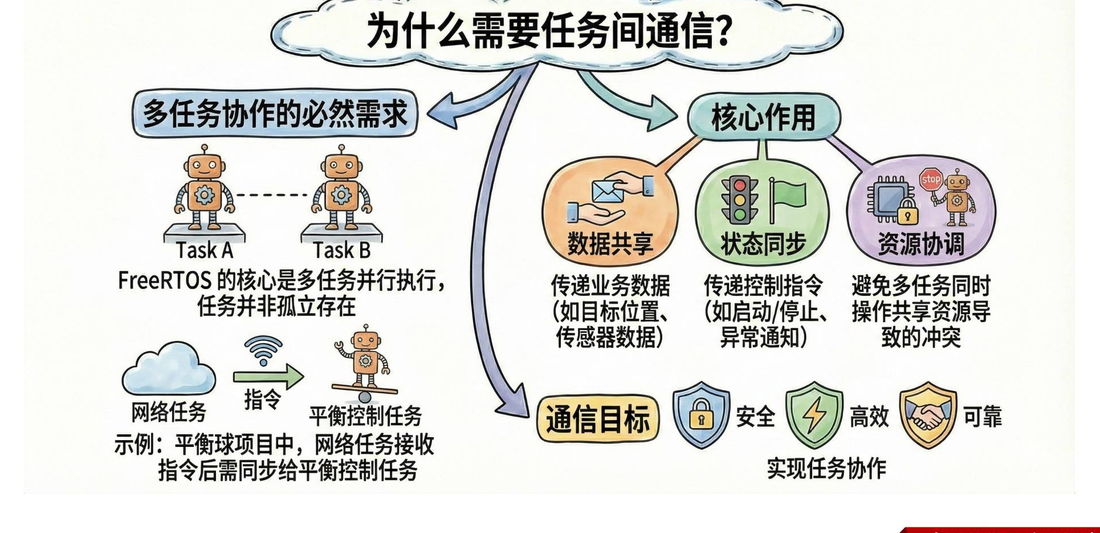

FreeRTOS 中的每个任务都有自己的栈和执行上下文。任务独立运行有利于拆分功能，但一个完整系统又必须让任务交换信息。例如：网络任务收到新的目标位置后，需要让平衡控制任务使用这个目标；传感器任务采集到距离后，需要把结果交给避障任务；按键任务产生事件后，需要通知显示任务刷新界面。

任务间通信主要解决三类问题：

1. **传递事件**：告诉另一个任务“某件事已经发生”。
2. **传递数据**：把数值、结构体或指令包交给另一个任务。
3. **协调资源**：让多个任务按照规则访问同一份资源。

通信机制还需要定义发送方和接收方的关系。发送方可能短时间连续产生多条数据，而接收方处理速度较慢；这时需要缓冲。若只是一次性的唤醒，则不应为了一个简单事件建立复杂的数据通道。


## 3. 全局变量通信：简单但有边界

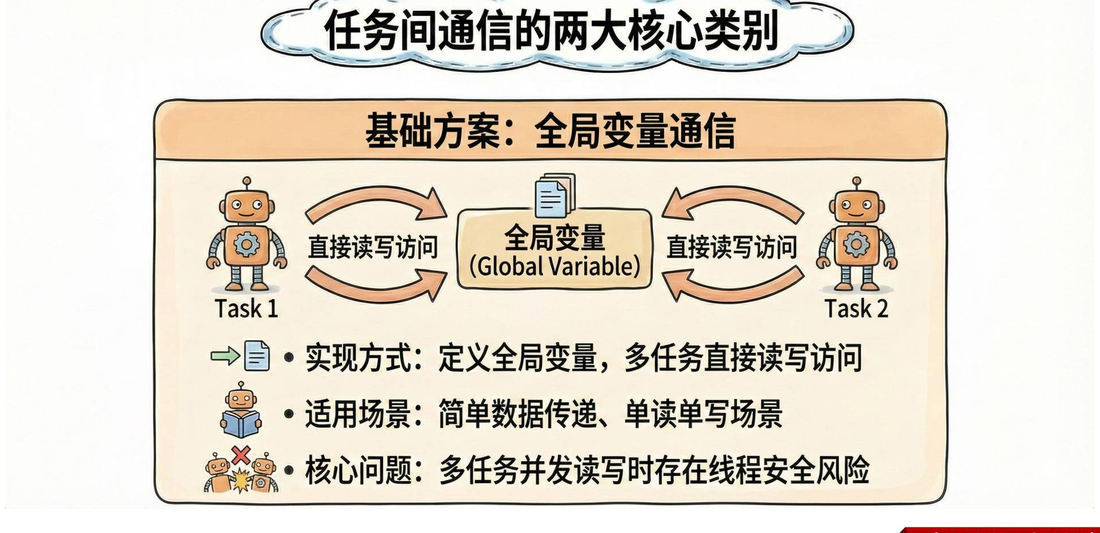

最直接的做法是定义一个所有任务都能访问的全局变量：

```c
volatile int g_target_position;

void network_task(void *argument)
{
    g_target_position = 200;       // 网络任务写入目标位置
    vTaskDelay(pdMS_TO_TICKS(10));
}

void balance_task(void *argument)
{
    int target = g_target_position; // 平衡控制任务读取目标位置
    balance_pid_update(target);
}
```

这种方式适合简单的**单写多读**状态，例如一个任务更新当前模式，多个任务只读取模式。它代码少、开销低，调试时也容易观察。

但是，全局变量只表达了“某个地址上的最新值”，没有表达数据何时更新、是否已经被消费、连续写入是否需要排队等语义。如果接收方必须知道每一次变化，单纯读取全局变量就可能丢失中间值。

`volatile` 只能提醒编译器每次从内存读取，不能保证复合数据的原子性，也不能解决任务之间的先后关系。要表达同步和数据传递，应优先使用 FreeRTOS 提供的通信对象。


## 4. 全局变量的线程安全风险

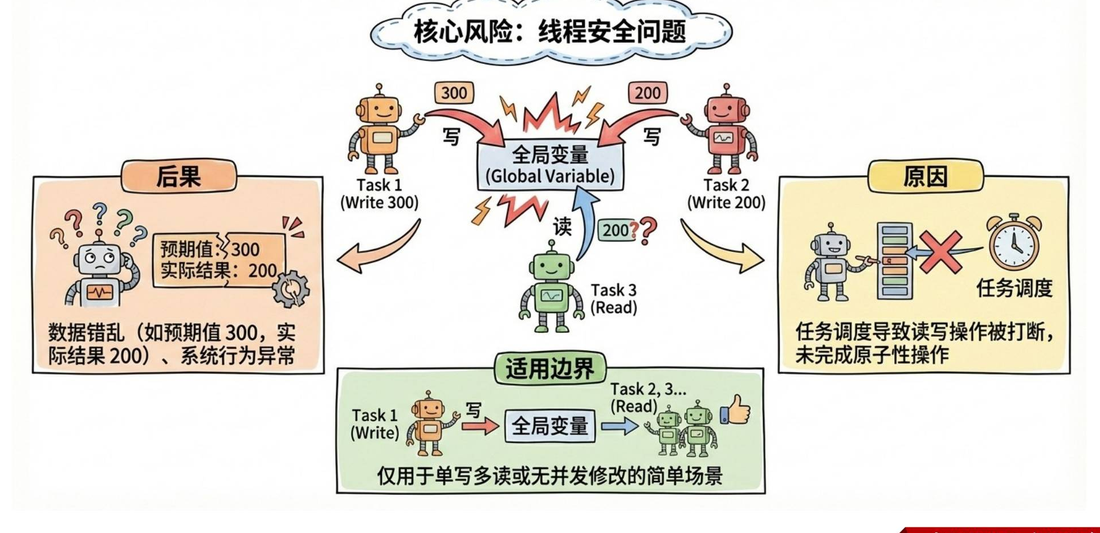

多个任务同时访问全局变量时，风险来自**数据竞争**而不是变量是否写成了 `volatile`。例如一个任务更新结构体的多个字段，另一个任务恰好在更新到一半时读取，就可能得到字段来自不同时间点的混合状态。

```c
typedef struct {
    int x;
    int y;
} TargetPosition;

static TargetPosition g_target;

// 任务 A 可能先写 x，再写 y
g_target.x = new_x;
g_target.y = new_y;

// 任务 B 可能在两次写入之间读取到不一致的坐标
TargetPosition copy = g_target;
```

如果确实要共享一个简单变量，应先明确访问模型：谁负责写、谁负责读、是否允许覆盖旧值、读写是否是单条原子操作。对于多个字段、读改写操作或多个写入者，需要用互斥量/临界区保护，或者改用消息队列传递一份完整快照。

工程判断可以按下面几步进行：

1. 只需要最新状态且只有一个写入者时，才考虑全局变量。
2. 需要每条数据都被接收时，使用消息队列等带缓冲机制。
3. 需要保护外设、文件或共享缓冲区时，使用互斥信号量。
4. 需要通知“更新完成”时，把数据和通知的先后关系一起设计，避免接收方读到半成品。


## 5. FreeRTOS 四种原生通信方式总览

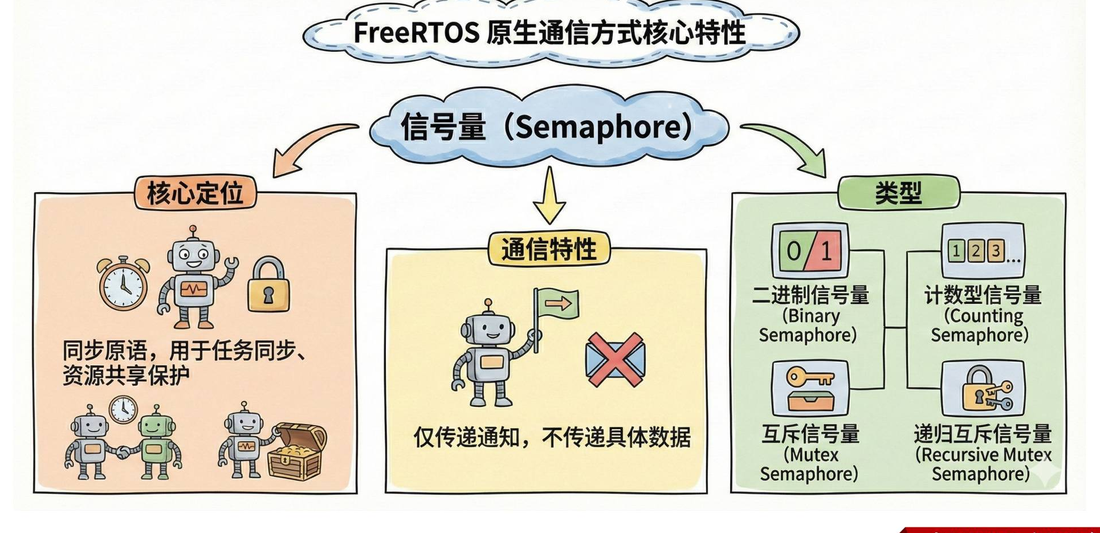

课件将常用原生机制归纳为四类：

| 机制 | 能否携带具体数据 | 是否有缓冲 | 典型用途 |
|---|---:|---:|---|
| 信号量 | 否，主要表达通知或资源数量 | 视类型而定 | 同步、事件通知、资源保护 |
| 消息队列 | 是，可复制字节、数值或结构体 | 是 | 异步传递指令和传感器数据 |
| 事件组 | 否，只保存多个事件位 | 是状态位 | 等待多个条件的与/或组合 |
| 直达任务通知 | 可携带少量值或位 | 每个任务的通知槽 | 轻量级唤醒和简单状态传递 |

四种机制都可以用于任务与任务之间，也有对应的 ISR 版本接口（名称通常带 `FromISR`）。选择时先描述通信语义，再选择 API：是“有一个事件发生”，还是“有一条数据到达”，还是“几个条件同时满足”，还是“多个任务争用一个资源”。


## 6. 信号量：通知、同步与资源保护

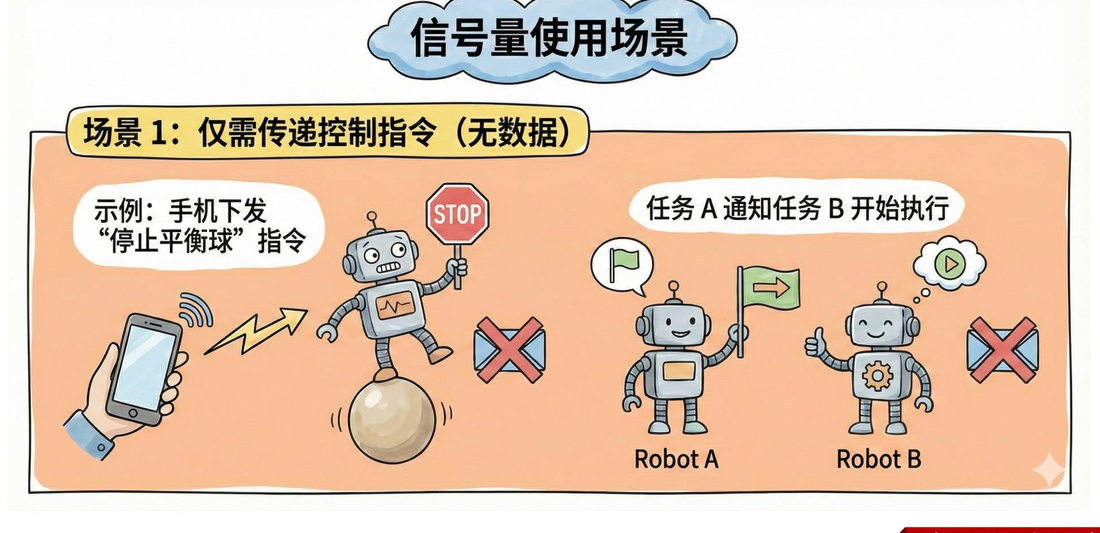

信号量主要传递**通知或许可**，不负责携带一段业务数据。FreeRTOS 中常见的类型有：

| 类型 | 语义 | 常见场景 |
|---|---|---|
| 二值信号量 | 只有“有/无”两种状态 | 任务同步、ISR 通知任务、一次性事件 |
| 计数信号量 | 保存可用资源的数量 | 统计资源、连接数、空闲缓冲块 |
| 互斥信号量 | 带所有权的资源锁 | 保护 UART、共享外设或共享数据 |
| 递归互斥信号量 | 同一任务可递归获取 | 已明确需要嵌套加锁的调用链 |

典型的二值信号量流程如下：

```c
SemaphoreHandle_t data_ready;

// 创建后由生产者释放，消费者等待
data_ready = xSemaphoreCreateBinary();

// 生产者：事件发生
xSemaphoreGive(data_ready);

// 消费者：等待事件
if (xSemaphoreTake(data_ready, portMAX_DELAY) == pdTRUE) {
    handle_data_ready();
}
```

互斥信号量用于保护资源访问，不能把它当作普通事件通知的替代品。若任务只是等待“数据到达”，用二值信号量或任务通知；若任务需要锁住共享资源，才使用互斥信号量。


## 7. 消息队列：带数据的异步通信

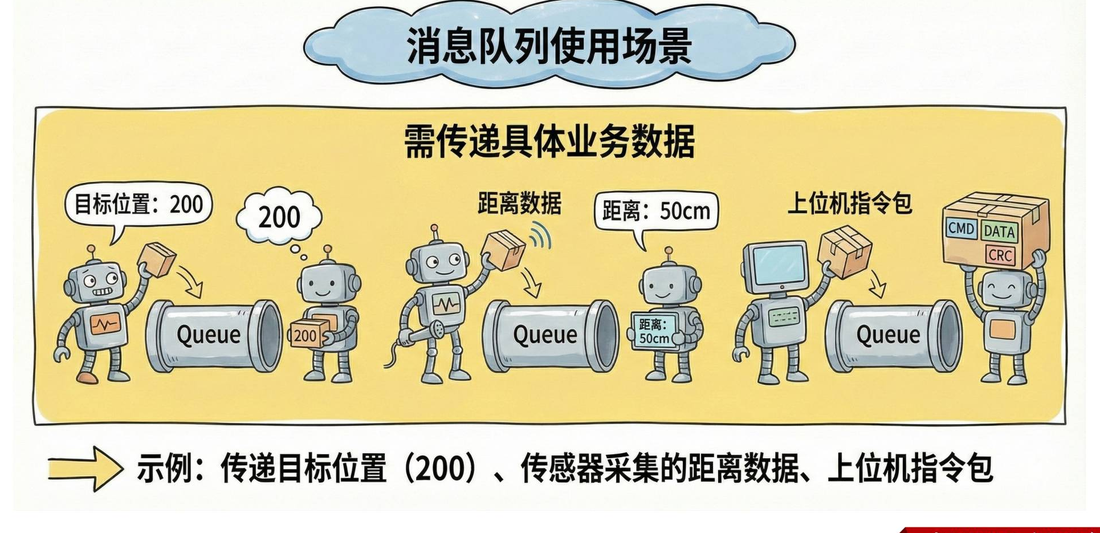

消息队列既能传递通知，也能传递具体数据。发送者把一条消息复制到队列存储区，接收者再从队列取出。消息可以是字节、整数、结构体或固定格式的指令包。

```c
typedef struct {
    int target_position;
    uint32_t timestamp;
} TargetCommand;

QueueHandle_t command_queue;

command_queue = xQueueCreate(8, sizeof(TargetCommand));

TargetCommand command = { .target_position = 200, .timestamp = 1000 };
xQueueSend(command_queue, &command, pdMS_TO_TICKS(10));

TargetCommand received;
if (xQueueReceive(command_queue, &received, portMAX_DELAY) == pdPASS) {
    apply_target(received.target_position);
}
```

队列长度和单条消息大小在创建时确定。队列具有缓冲能力：生产者短时间产生多条消息时，接收任务可以稍后处理，从而减少因任务切换或瞬时忙碌造成的数据丢失。课件举例的目标位置、传感器距离、上位机指令包，都适合用队列表达。

需要注意：队列会复制消息内容，因此传递结构体时应确认结构体大小和生命周期；如果传递指针，则必须额外管理指针指向的内存，避免接收方拿到悬空地址。队列满时要根据业务决定阻塞等待、丢弃新消息，还是覆盖旧消息。


## 8. 事件组：多个事件的组合触发

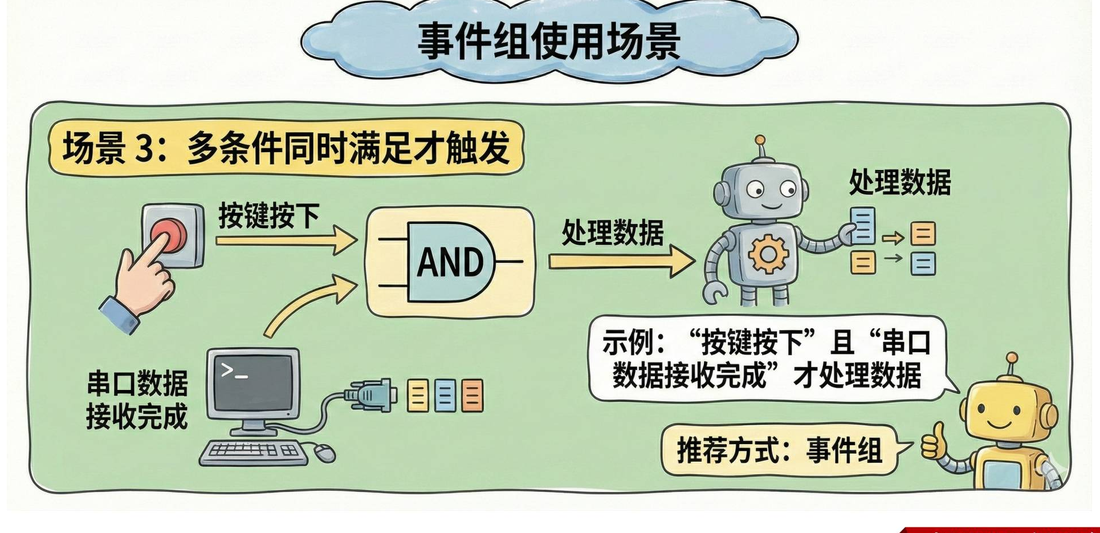

事件组用一个位图保存多个事件状态，每一位代表一种条件，例如：

```c
#define EVENT_KEY_PRESSED   (1 << 0)
#define EVENT_UART_RECEIVED (1 << 1)
#define EVENT_SENSOR_READY  (1 << 2)

EventGroupHandle_t events;
events = xEventGroupCreate();

// 等待“按键且串口接收完成”两个条件同时满足
EventBits_t bits = xEventGroupWaitBits(
    events,
    EVENT_KEY_PRESSED | EVENT_UART_RECEIVED,
    pdTRUE,   // 退出前清除满足的位
    pdTRUE,    // pdTRUE 表示等待所有位；pdFALSE 表示任一位即可
    portMAX_DELAY);

if ((bits & (EVENT_KEY_PRESSED | EVENT_UART_RECEIVED)) ==
    (EVENT_KEY_PRESSED | EVENT_UART_RECEIVED)) {
    process_command();
}
```

事件组只传递“哪些条件已经发生”，不传递目标位置、距离等具体数据。它适合多条件触发：使用“或”逻辑时任意一个事件位到达即可唤醒，使用“与”逻辑时必须等指定的多个位都置位。

设计时要明确事件位由谁设置、由谁清除，以及一个事件是否允许被多个任务同时观察。若事件位只是状态而不是计数，连续设置同一位多次不会保存次数；需要统计每次发生的数量时，应使用计数信号量或消息队列。


## 9. 直达任务通知：轻量级任务通信

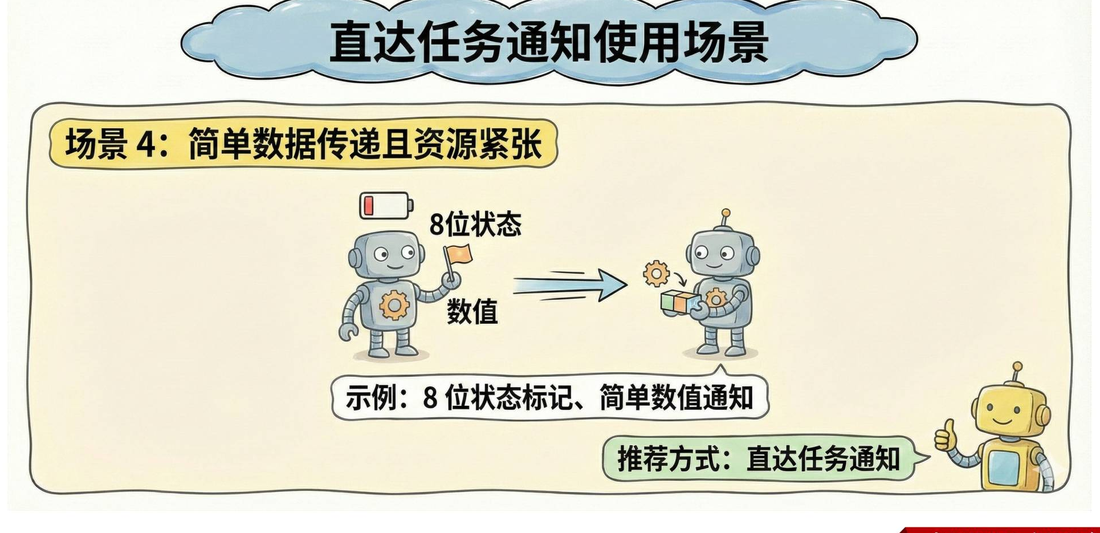

直达任务通知把通知状态直接放在目标任务的通知槽中，不需要单独创建信号量或队列对象。它可以用于简单的唤醒，也可以携带一个小的数值或位图；课件将其概括为可携带约4字节的数据。

```c
// 发送方：通知指定任务，并携带一个简单状态值
xTaskNotify(task_handle, 200, eSetValueWithOverwrite);

// 接收方：等待通知并取出值
uint32_t value;
if (xTaskNotifyWait(0, 0, &value, portMAX_DELAY) == pdTRUE) {
    consume_status(value);
}
```

任务通知的优点是效率高、资源占用少、路径直接，适合简单状态值、轻量级事件和单一接收任务。它的限制也很明确：通知槽属于任务，默认不适合作为多个接收者共享的公共消息池；相比消息队列，它不能自然地保存任意长度的多条结构化消息。

如果通信只需要唤醒一个确定的任务，任务通知通常比创建一个二值信号量更轻。如果需要多个消费者、消息排队或复制结构体，则应选择消息队列；如果需要多个事件位的组合等待，则选择事件组。


## 10. 通信方式对比与工程选型

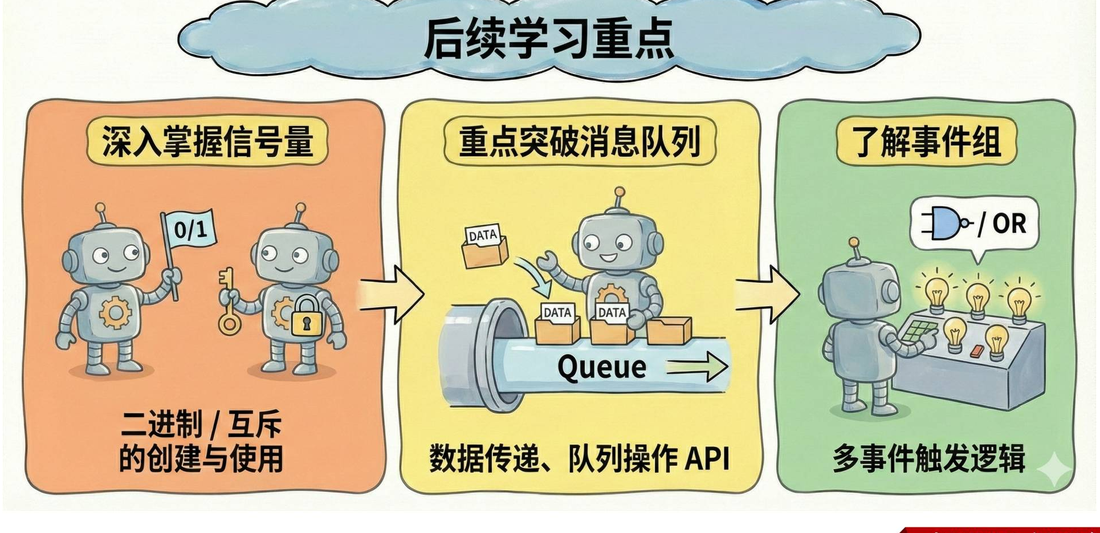

可以用下面的决策表快速选型：

| 需求 | 优先考虑 | 原因 |
|---|---|---|
| 只通知一次事件发生 | 二值信号量或任务通知 | 语义简单，开销小 |
| 统计资源数量或事件次数 | 计数信号量 | 内核保存计数 |
| 保护共享外设和共享数据 | 互斥信号量 | 有所有权和优先级继承语义 |
| 传递结构体、指令包、传感器值 | 消息队列 | 复制数据并提供缓冲 |
| 等待多个条件的“与/或”组合 | 事件组 | 用多个事件位表达状态 |
| 单一任务的轻量唤醒或少量数值 | 直达任务通知 | 直接到达任务，资源占用少 |

选型还要考虑发送速度和接收速度。如果生产者可能突发发送，队列长度必须结合峰值速率和最坏处理时间估算；如果只关心最新状态，可以采用覆盖式消息或受保护的共享变量；如果必须保留每次变化，就不能用会覆盖旧值的方案。

不要把“通知”和“资源保护”混为一谈。二值信号量可以同步任务，但互斥信号量才表达对资源的所有权。也不要为了传递一个整数就建立复杂的多字段队列，通信对象的语义应与需求相匹配。


## 11. 本课要点与验证步骤

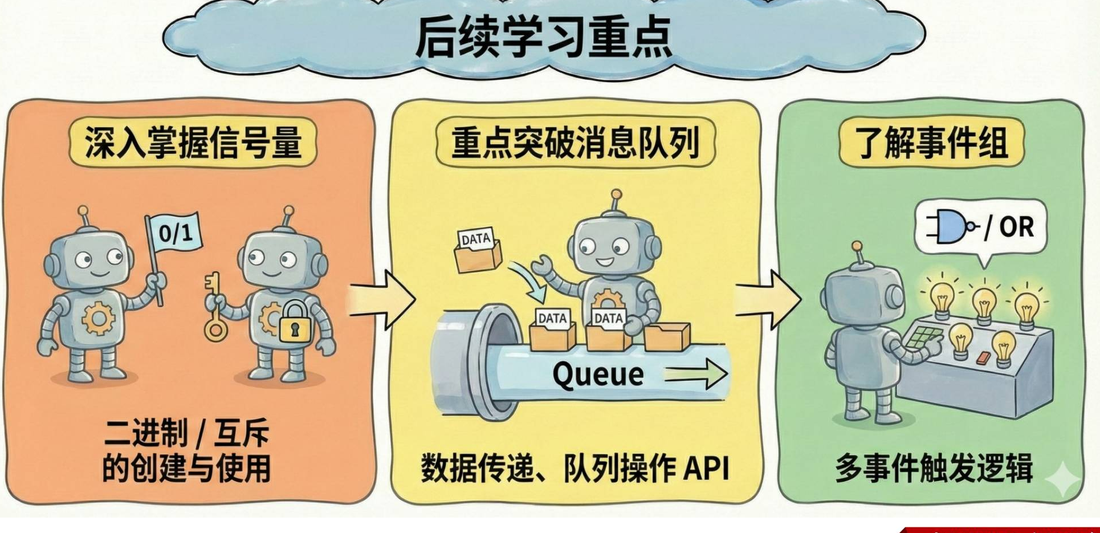

课件总结的核心是：全局变量适合简单的单写多读状态，但并发读写存在数据竞争；FreeRTOS 原生机制中，信号量负责通知、同步和资源保护，消息队列负责带缓冲的数据传递，事件组负责多事件组合，直达任务通知负责高效的轻量级任务通信。

在课程工程中可以按以下顺序核对：

1. 先写清楚通信对象的语义：事件、数据、资源，还是多个条件。
2. 检查全局变量是否存在多个写入者、复合结构体半更新和读改写竞争。
3. 检查二值信号量、计数信号量和互斥信号量是否按语义使用，避免用互斥量传递普通事件。
4. 检查消息队列的长度、单条消息大小、满队列策略和发送/接收超时。
5. 检查事件组的位定义、等待逻辑（“与”还是“或”）以及清除时机。
6. 检查任务通知的目标任务、通知值覆盖策略和是否确实只有一个接收者。
7. 在 ISR 中发送通信对象时使用对应的 `FromISR` API，并检查是否需要请求任务切换。
8. 对通信对象的创建、删除和句柄访问建立清晰的生命周期和所有权规则。

同名副本第18页把后续重点归纳为：深入学习二值信号量和互斥信号量，重点掌握消息队列的数据传递与 API，了解事件组的多事件触发逻辑。本篇内容依据主课件和该补充页整理，未进行开发板编译、下载或运行。
